# Investigação Experimental de Filtros de Aguçamento Espacial (Sharpening) em Escalogramas CWT

**Projeto:** Diagnóstico de Falhas em Rolamentos Industriais via CWT + CNN  
**Módulo 7:** Filtros de Aguçamento Espacial (*Sharpening Filters*)  
**Caso de Estudo:** Arquitetura `BearingCNN` no Dataset **XJTU-SY** sob Particionamento Estrito (*Leave-Bearing-Out*)  
**Classes:** 3 Classes (`inner_race`, `normal`, `outer_race`)  

---

### 1. Contexto Científico e Motivação do Experimento

No benchmark tripartite deste projeto, o dataset **XJTU-SY** representou o cenário intra-domínio mais desafiador:
1. **Isolamento Total de Rolamentos Físicos (*Leave-Bearing-Out*):** O conjunto de teste é composto exclusivamente por três mancais nunca vistos durante o treinamento (`Bearing3_1` normal, `Bearing3_4` falha na pista interna e `Bearing3_5` falha na pista externa) operando sob rotação inédita de 40 Hz ($2.400\text{ RPM}$) e carga radial pesada de $10\text{ kN}$.
2. **O Desempenho da BearingCNN:** Enquanto as arquiteturas pré-treinadas no ImageNet (*ResNet-18*, *EfficientNet-B0* e *Inception-v3*) atingiram a faixa de **95,33% a 95,78%**, a `BearingCNN` (0,52 M parâmetros treinada do zero) obteve **71,78%** de acurácia multiclasse.
3. **Diagnóstico do Gargalo da BearingCNN:** Uma análise aprofundada da matriz de confusão e do relatório de classificação revelou que o gargalo esteve concentrado na classe **pista interna (`inner_race`)**, cujo *recall* foi de apenas **16,00%** (126 de 150 amostras foram incorretamente rotuladas como pista externa).

#### Por que filtros de aguçamento podem ajudar?
A Transformada Wavelet Contínua (CWT) com wavelet-mãe Morlet complexa introduz um espalhamento gaussiano natural no plano tempo-frequência. Sob condições severas de carga mecânica ($10\text{ kN}$) e ressonâncias de bancada, as assinaturas impulsivas de impacto da pista interna tendem a sofrer borramento (*blurring*), obscurecendo as finas estrias verticais de passagem dos elementos rolantes. 

Os **filtros de aguçamento espacial** (*sharpening*) atuam como filtros passa-altas espaciais, realçando transições abruptas de intensidade e bordas nos escalogramas. Este notebook investiga duas técnicas fundamentais de Processamento Digital de Imagens (PDI):
* **Unsharp Masking (Máscara de Desfoque):** $I_{\text{sharp}} = I + \alpha \cdot (I - I_{\text{blur}})$, com parâmetros de raio $\sigma$, fator de amplificação $\alpha$ e limiar (*threshold*) que atua como porta de ruído (*noise gate*) para impedir a amplificação do ruído de fundo.
* **Filtro Laplaciano (2ª Derivada Espacial):** Convolução com kernel isotrópico $3 \times 3$, enfatizando gradientes de intensidade de segunda ordem.

---


## 1. Importação de Módulos e Configurações Iniciais


In [1]:
import sys
from pathlib import Path

# Ajuste dinâmico de caminho para o diretório raiz do projeto
if Path.cwd().name == '7_filtros_agucamento':
    BASE_DIR = Path.cwd().parent.parent
elif Path.cwd().name == 'notebooks':
    BASE_DIR = Path.cwd().parent
else:
    BASE_DIR = Path.cwd()

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

from src.config import (
    XJTU_PROCESSED_DIR,
    XJTU_CLASSES,
    BATCH_SIZE,
    LEARNING_RATE,
    NUM_EPOCHS,
    RANDOM_SEED,
    IMG_HEIGHT,
    IMG_WIDTH,
    set_seed
)
from src.cnn_processor import (
    BearingCNN,
    train_and_evaluate_bearing_cnn,
    get_data_loaders
)
from src.sharpening import (
    SharpenTransform,
    get_sharpen_transform,
    apply_sharpening_to_pil
)
from src.visualization import plot_training_curves, plot_confusion_matrix

# Fixação estrita da semente pseudoaleatória para reprodutibilidade
set_seed(RANDOM_SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[INFO] Ambiente pronto. Dispositivo ativo: {device}')
print(f'[INFO] Diretório XJTU processado: {XJTU_PROCESSED_DIR}')

[INFO] Ambiente pronto. Dispositivo ativo: cuda
[INFO] Diretório XJTU processado: C:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\data\xjtu\processed


## 2. Inspeção Visual Qualitativa: Escalograma Original vs. Filtros de Aguçamento

Antes de iniciar o treinamento das redes, visualizamos o impacto físico direto de cada filtro sobre amostras reais de teste do XJTU-SY nas 3 classes operacionais. Para cada classe, comparamos:
1. **Escalograma Original:** Gerado diretamente pela CWT (wavelet Morlet complexa);
2. **Unsharp Masking (Moderado):** Raio $\sigma=1.5$, ganho $=150\%$, limiar $=3$;
3. **Filtro Laplaciano ($3 \times 3$):** Realce de segunda derivada espacial;
4. **Mapa Residual de Contraste ($|I_{\text{sharp}} - I_{\text{orig}}| \times 3$):** Destaca exatamente as cristas e estrias onde o filtro injetou nitidez mecânica.


[INFO] Figura comparativa salva em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\agucamento_comparacao_visual_escalogramas.png


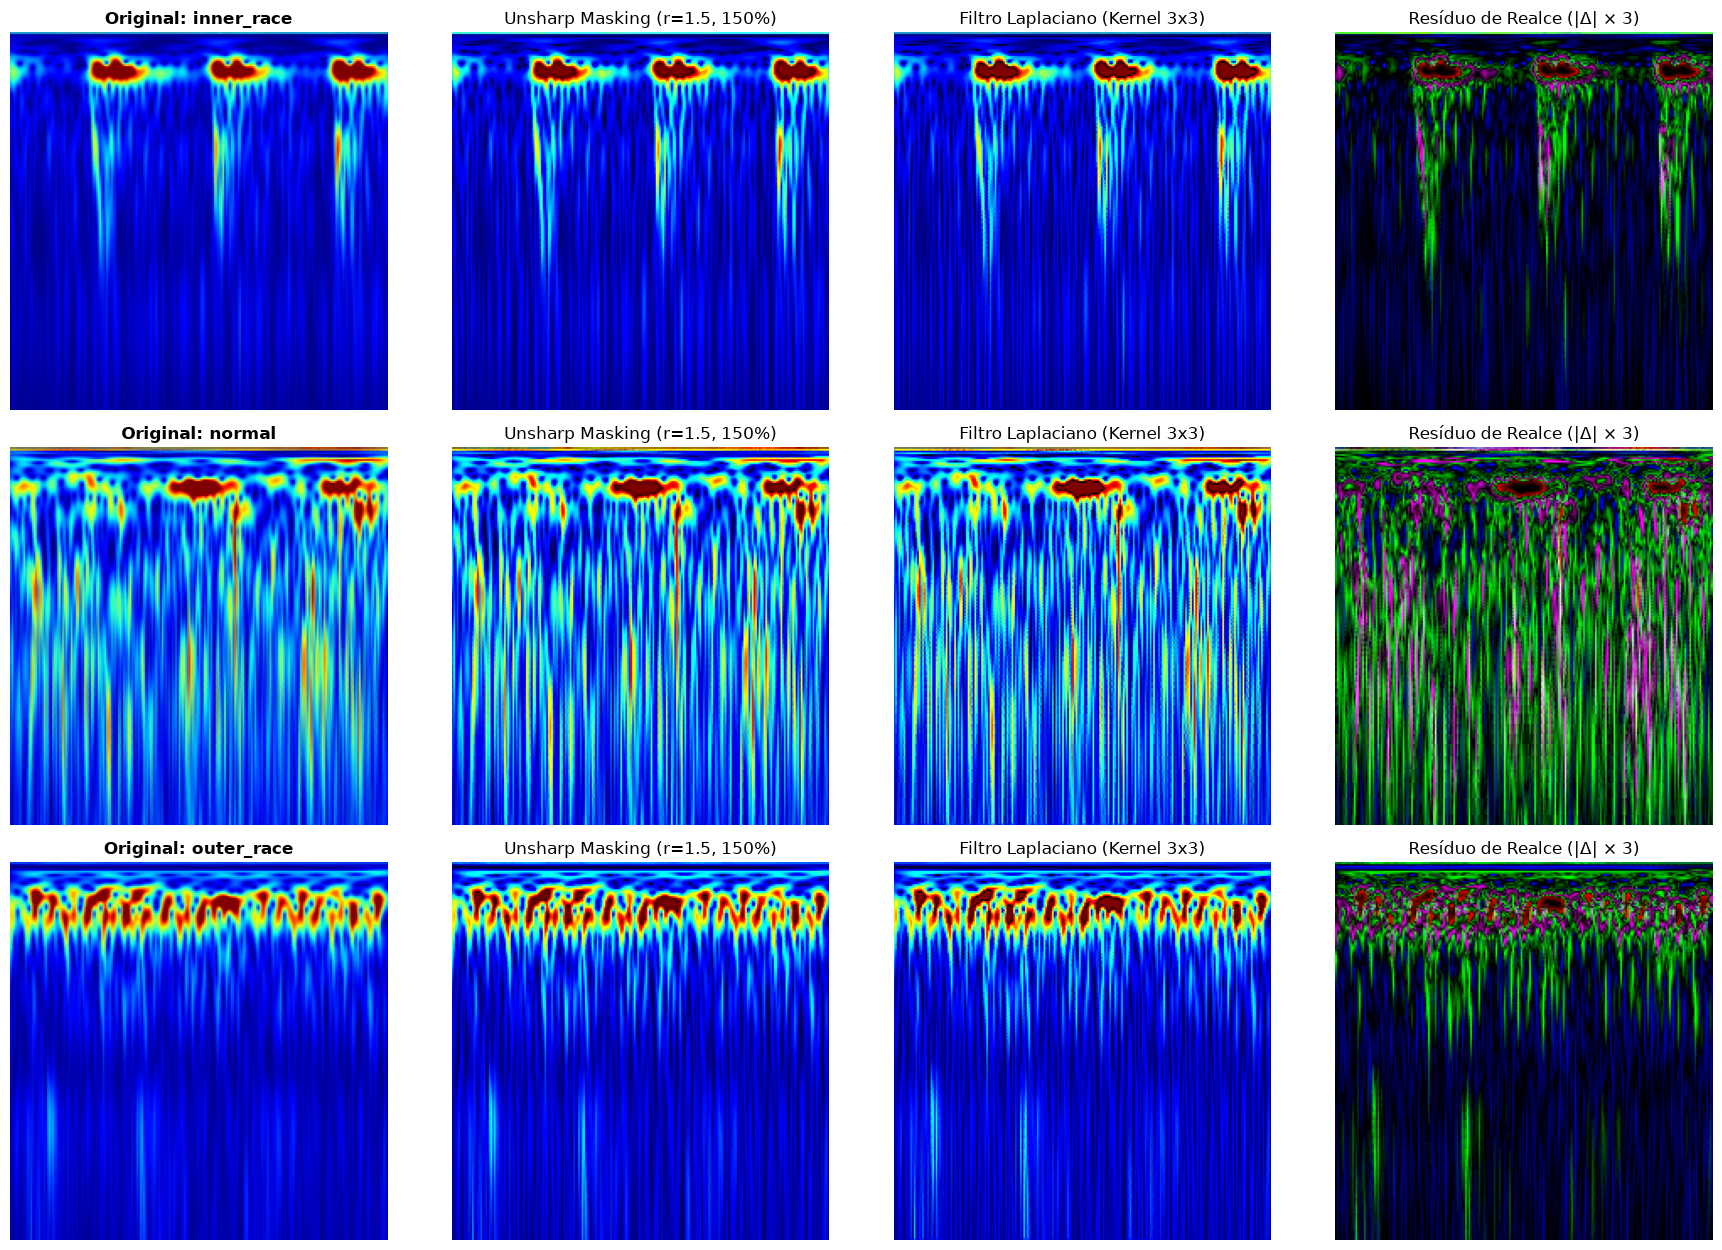

In [2]:
test_dir = XJTU_PROCESSED_DIR / 'test'
classes_disponiveis = [c.name for c in sorted(test_dir.iterdir()) if c.is_dir()]

sample_images = {}
for c in classes_disponiveis:
    imgs = sorted(list((test_dir / c).glob('*.png')))
    if imgs:
        sample_images[c] = Image.open(imgs[0]).convert('RGB')

fig, axes = plt.subplots(len(classes_disponiveis), 4, figsize=(18, 4.2 * len(classes_disponiveis)))

for row_idx, (cls_name, img_orig) in enumerate(sample_images.items()):
    # 1. Original
    axes[row_idx, 0].imshow(img_orig)
    axes[row_idx, 0].set_title(f'Original: {cls_name}', fontsize=12, fontweight='bold')
    axes[row_idx, 0].axis('off')
    
    # 2. Unsharp Masking
    img_unsharp, diff_unsharp = apply_sharpening_to_pil(img_orig, method='unsharp', radius=1.5, percent=150, threshold=3)
    axes[row_idx, 1].imshow(img_unsharp)
    axes[row_idx, 1].set_title('Unsharp Masking (r=1.5, 150%)', fontsize=12)
    axes[row_idx, 1].axis('off')
    
    # 3. Laplaciano 3x3
    img_laplace, diff_laplace = apply_sharpening_to_pil(img_orig, method='laplacian')
    axes[row_idx, 2].imshow(img_laplace)
    axes[row_idx, 2].set_title('Filtro Laplaciano (Kernel 3x3)', fontsize=12)
    axes[row_idx, 2].axis('off')
    
    # 4. Mapa Residual de Aguçamento (|Delta| x 3)
    res_map = np.clip(diff_unsharp * 3.0, 0, 255).astype(np.uint8)
    axes[row_idx, 3].imshow(res_map)
    axes[row_idx, 3].set_title('Resíduo de Realce (|Δ| × 3)', fontsize=12)
    axes[row_idx, 3].axis('off')

plt.tight_layout()
out_fig_path = BASE_DIR / 'docs' / 'images' / 'agucamento_comparacao_visual_escalogramas.png'
out_fig_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_fig_path, dpi=300, bbox_inches='tight')
print(f'[INFO] Figura comparativa salva em: {out_fig_path}')
plt.show()

## 3. Experimento 1: Treinamento do Modelo Baseline (Sem Aguçamento)

Treinamos a arquitetura convolucional `BearingCNN` (0,52 M parâmetros) a partir de pesos aleatórios pelo protocolo padrão do projeto (10 épocas, otimizador Adam com $\text{LR} = 5 \times 10^{-5}$, `batch_size = 32`, semente 42) utilizando os escalogramas CWT originais.


In [3]:
print('=' * 80)
print(' EXPERIMENTO 1: BEARINGCNN BASELINE (SEM AGUÇAMENTO)')
print('=' * 80)

checkpoint_baseline = 'checkpoint_xjtu_bearing_cnn_baseline.pth'

resultado_baseline = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=XJTU_PROCESSED_DIR,
    checkpoint_name=checkpoint_baseline,
    seed=RANDOM_SEED,
    custom_transform=None
)

print(f'\n[BASELINE FINALIZADO] Acurácia no Teste: {resultado_baseline["test_acc"]:.2f}%')

 EXPERIMENTO 1: BEARINGCNN BASELINE (SEM AGUÇAMENTO)
[INFO] EXPERIMENTO BEARING CNN (PRÓPRIA) | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.8191 - Acc: 75.42% | Val Loss: 0.7679 - Acc: 80.19% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.5402 - Acc: 87.92% | Val Loss: 0.3856 - Acc: 93.89% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.3977 - Acc: 92.50% | Val Loss: 0.2514 - Acc: 94.81% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.3233 - Acc: 92.50% | Val Loss: 0.2503 - Acc: 92.59% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.2627 - Acc: 94.03% | Val Loss: 0.2130 - Acc: 93.15% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.2158 - Acc: 95.28% | Val Loss: 0.1834 - Acc: 95.00% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.1770 - Acc: 96.25% | Val Loss: 0.1963 - Acc: 94.07% 
Época [08/10]

In [4]:
print('\n' + '=' * 70)
print(' RELATÓRIO DE CLASSIFICAÇÃO NO TESTE — BASELINE (SEM AGUÇAMENTO)')
print('=' * 70)
report_baseline = classification_report(
    resultado_baseline['test_labels'],
    resultado_baseline['test_preds'],
    target_names=resultado_baseline['classes'],
    digits=4
)
print(report_baseline)


 RELATÓRIO DE CLASSIFICAÇÃO NO TESTE — BASELINE (SEM AGUÇAMENTO)
              precision    recall  f1-score   support

  inner_race     0.9600    0.1600    0.2743       150
      normal     1.0000    0.9933    0.9967       150
  outer_race     0.5435    1.0000    0.7042       150

    accuracy                         0.7178       450
   macro avg     0.8345    0.7178    0.6584       450
weighted avg     0.8345    0.7178    0.6584       450



## 4. Experimento 2: Treinamento com Filtro Unsharp Masking

Injetamos a transformação `SharpenTransform(method='unsharp', radius=1.5, percent=150, threshold=3)` no DataLoader através da função `get_sharpen_transform()`. As imagens são aguçadas dinamicamente durante o carregamento de treino, validação e teste, preservando o armazenamento em disco e garantindo distribuição homogênea em todos os splits.


In [5]:
transform_unsharp = get_sharpen_transform(
    method='unsharp',
    radius=1.5,
    percent=150,
    threshold=3
)

print('=' * 80)
print(' EXPERIMENTO 2: BEARINGCNN COM UNSHARP MASKING (r=1.5, 150%, thr=3)')
print('=' * 80)

checkpoint_unsharp = 'checkpoint_xjtu_bearing_cnn_unsharp.pth'

resultado_unsharp = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=XJTU_PROCESSED_DIR,
    checkpoint_name=checkpoint_unsharp,
    seed=RANDOM_SEED,
    custom_transform=transform_unsharp
)

print(f'\n[UNSHARP FINALIZADO] Acurácia no Teste: {resultado_unsharp["test_acc"]:.2f}%')

 EXPERIMENTO 2: BEARINGCNN COM UNSHARP MASKING (r=1.5, 150%, thr=3)
[INFO] EXPERIMENTO BEARING CNN (PRÓPRIA) | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.8107 - Acc: 75.28% | Val Loss: 0.7265 - Acc: 89.07% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.5455 - Acc: 88.33% | Val Loss: 0.3985 - Acc: 92.41% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.4118 - Acc: 92.22% | Val Loss: 0.2630 - Acc: 94.63% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.3392 - Acc: 91.94% | Val Loss: 0.2542 - Acc: 93.15% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.2810 - Acc: 93.33% | Val Loss: 0.2092 - Acc: 93.33% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.2322 - Acc: 94.72% | Val Loss: 0.1688 - Acc: 95.19% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.1934 - Acc: 95.97% | Val Loss: 0.1771 - Acc: 94.63%

In [6]:
print('\n' + '=' * 70)
print(' RELATÓRIO DE CLASSIFICAÇÃO NO TESTE — COM UNSHARP MASKING')
print('=' * 70)
report_unsharp = classification_report(
    resultado_unsharp['test_labels'],
    resultado_unsharp['test_preds'],
    target_names=resultado_unsharp['classes'],
    digits=4
)
print(report_unsharp)


 RELATÓRIO DE CLASSIFICAÇÃO NO TESTE — COM UNSHARP MASKING
              precision    recall  f1-score   support

  inner_race     0.9444    0.1133    0.2024       150
      normal     1.0000    0.9933    0.9967       150
  outer_race     0.5300    1.0000    0.6928       150

    accuracy                         0.7022       450
   macro avg     0.8248    0.7022    0.6306       450
weighted avg     0.8248    0.7022    0.6306       450



## 5. Experimento 3: Treinamento com Filtro Laplaciano ($3 \times 3$)

Avaliamos o efeito do filtro derivativo Laplaciano isotrópico. Ao contrário do Unsharp Masking que possui um *threshold* atenuador de ruído, o Laplaciano puro amplifica derivadas espaciais diretamente. Este teste permite quantificar se uma abordagem puramente baseada em bordas beneficia ou satura a convolução da `BearingCNN`.


In [7]:
transform_laplacian = get_sharpen_transform(
    method='laplacian'
)

print('=' * 80)
print(' EXPERIMENTO 3: BEARINGCNN COM FILTRO LAPLACIANO (KERNEL 3x3)')
print('=' * 80)

checkpoint_laplacian = 'checkpoint_xjtu_bearing_cnn_laplacian.pth'

resultado_laplacian = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=XJTU_PROCESSED_DIR,
    checkpoint_name=checkpoint_laplacian,
    seed=RANDOM_SEED,
    custom_transform=transform_laplacian
)

print(f'\n[LAPLACIANO FINALIZADO] Acurácia no Teste: {resultado_laplacian["test_acc"]:.2f}%')

 EXPERIMENTO 3: BEARINGCNN COM FILTRO LAPLACIANO (KERNEL 3x3)
[INFO] EXPERIMENTO BEARING CNN (PRÓPRIA) | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.8025 - Acc: 75.69% | Val Loss: 0.7066 - Acc: 89.81% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.5375 - Acc: 88.75% | Val Loss: 0.3883 - Acc: 92.04% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.4059 - Acc: 92.08% | Val Loss: 0.2536 - Acc: 94.63% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.3372 - Acc: 91.53% | Val Loss: 0.2454 - Acc: 93.15% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.2818 - Acc: 93.06% | Val Loss: 0.2048 - Acc: 93.70% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.2369 - Acc: 94.03% | Val Loss: 0.1612 - Acc: 95.74% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.2018 - Acc: 95.14% | Val Loss: 0.1701 - Acc: 95.19% 
Époc

In [8]:
print('\n' + '=' * 70)
print(' RELATÓRIO DE CLASSIFICAÇÃO NO TESTE — COM FILTRO LAPLACIANO')
print('=' * 70)
report_laplacian = classification_report(
    resultado_laplacian['test_labels'],
    resultado_laplacian['test_preds'],
    target_names=resultado_laplacian['classes'],
    digits=4
)
print(report_laplacian)


 RELATÓRIO DE CLASSIFICAÇÃO NO TESTE — COM FILTRO LAPLACIANO
              precision    recall  f1-score   support

  inner_race     0.9231    0.0800    0.1472       150
      normal     1.0000    0.9933    0.9967       150
  outer_race     0.5208    1.0000    0.6849       150

    accuracy                         0.6911       450
   macro avg     0.8146    0.6911    0.6096       450
weighted avg     0.8146    0.6911    0.6096       450



## 6. Confronto Geral de Desempenho e Matrizes de Confusão Comparativas

Nesta seção, consolidamos todas as métricas em uma tabela comparativa direta e plotamos as matrizes de confusão e as curvas de convergência lado a lado.


In [9]:
def extrair_metricas(res, nome):
    y_true = res['test_labels']
    y_pred = res['test_preds']
    classes = res['classes']
    
    acc = accuracy_score(y_true, y_pred) * 100.0
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None, labels=[0, 1, 2], zero_division=0)
    
    idx_normal = classes.index('normal')
    bin_true = [0 if y == idx_normal else 1 for y in y_true]
    bin_pred = [0 if y == idx_normal else 1 for y in y_pred]
    bin_acc = accuracy_score(bin_true, bin_pred) * 100.0
    
    idx_inner = classes.index('inner_race')
    idx_outer = classes.index('outer_race')
    
    return {
        'Estratégia': nome,
        'Acurácia Geral (%)': f'{acc:.2f}%',
        'Detecção Binária (%)': f'{bin_acc:.2f}%',
        'Recall Inner Race (%)': f'{rec[idx_inner]*100.0:.2f}%',
        'F1 Inner Race (%)': f'{f1[idx_inner]*100.0:.2f}%',
        'Recall Outer Race (%)': f'{rec[idx_outer]*100.0:.2f}%',
        'F1 Outer Race (%)': f'{f1[idx_outer]*100.0:.2f}%',
        'Melhor Val Acc (%)': f'{res["best_val_acc"]:.2f}%'
    }

df_confronto = pd.DataFrame([
    extrair_metricas(resultado_baseline, '1. Baseline (Sem Aguçamento)'),
    extrair_metricas(resultado_unsharp, '2. Com Unsharp Masking'),
    extrair_metricas(resultado_laplacian, '3. Com Filtro Laplaciano')
])

print('\n' + '=' * 100)
print(' TABELA COMPARATIVA DE DESEMPENHO NO XJTU-SY (LEAVE-BEARING-OUT)')
print('=' * 100)
display(df_confronto)

out_csv = BASE_DIR / 'results' / 'comparacao_agucamento_bearing_cnn.csv'
df_confronto.to_csv(out_csv, index=False)
print(f'[INFO] Tabela salva em: {out_csv}')


 TABELA COMPARATIVA DE DESEMPENHO NO XJTU-SY (LEAVE-BEARING-OUT)


,Estratégia,Acurácia Geral (%),Detecção Binária (%),Recall Inner Race (%),F1 Inner Race (%),Recall Outer Race (%),F1 Outer Race (%),Melhor Val Acc (%)
0,1. Baseline (Sem Aguçamento),71.78%,99.78%,16.00%,27.43%,100.00%,70.42%,95.00%
1,2. Com Unsharp Masking,70.22%,99.78%,11.33%,20.24%,100.00%,69.28%,95.19%
2,3. Com Filtro Laplaciano,69.11%,99.78%,8.00%,14.72%,100.00%,68.49%,95.74%


[INFO] Tabela salva em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\results\comparacao_agucamento_bearing_cnn.csv


[INFO] Matrizes de confusão comparativas salvas em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\agucamento_comparacao_matrizes_confusao.png


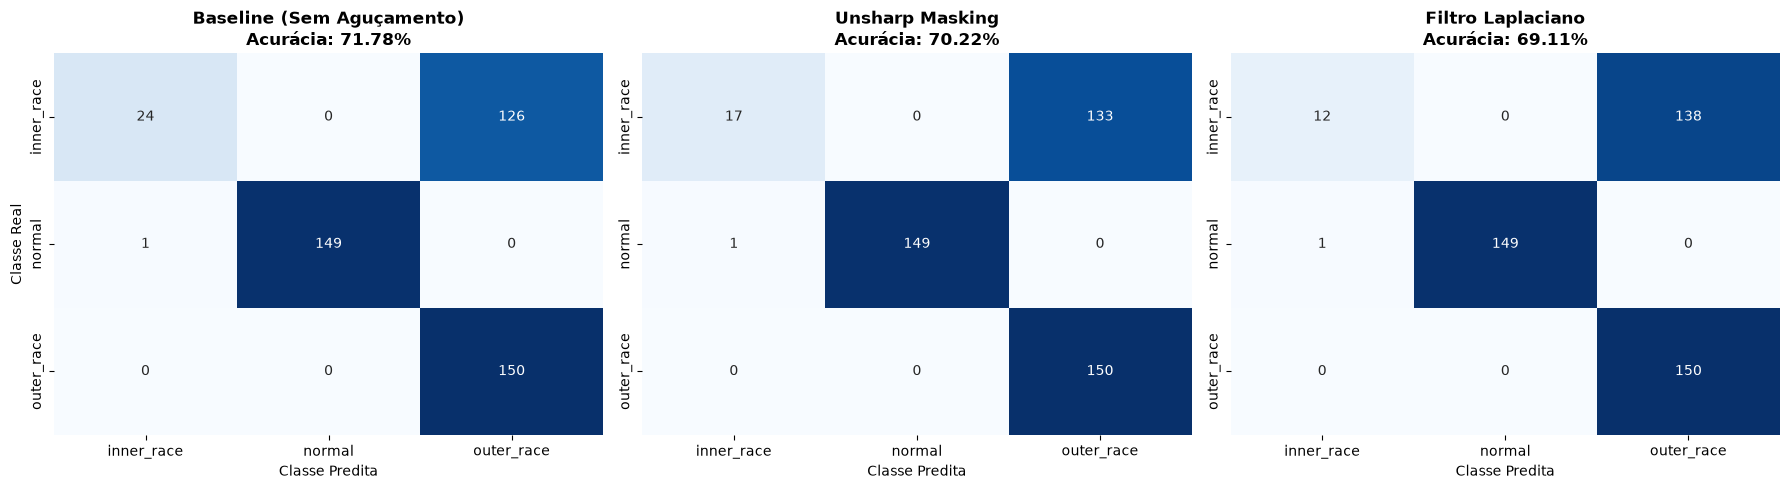

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

modelos_eval = [
    (resultado_baseline, 'Baseline (Sem Aguçamento)'),
    (resultado_unsharp, 'Unsharp Masking'),
    (resultado_laplacian, 'Filtro Laplaciano')
]

for idx, (res, titulo) in enumerate(modelos_eval):
    cm = confusion_matrix(res['test_labels'], res['test_preds'])
    acc = accuracy_score(res['test_labels'], res['test_preds']) * 100.0
    
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=res['classes'],
        yticklabels=res['classes'],
        ax=axes[idx],
        cbar=False
    )
    axes[idx].set_title(f'{titulo}\nAcurácia: {acc:.2f}%', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Classe Predita', fontsize=10)
    axes[idx].set_ylabel('Classe Real' if idx == 0 else '', fontsize=10)

plt.tight_layout()
out_cm_path = BASE_DIR / 'docs' / 'images' / 'agucamento_comparacao_matrizes_confusao.png'
plt.savefig(out_cm_path, dpi=300, bbox_inches='tight')
print(f'[INFO] Matrizes de confusão comparativas salvas em: {out_cm_path}')
plt.show()

[INFO] Curvas de treino comparativas salvas em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\agucamento_comparacao_curvas_treinamento.png


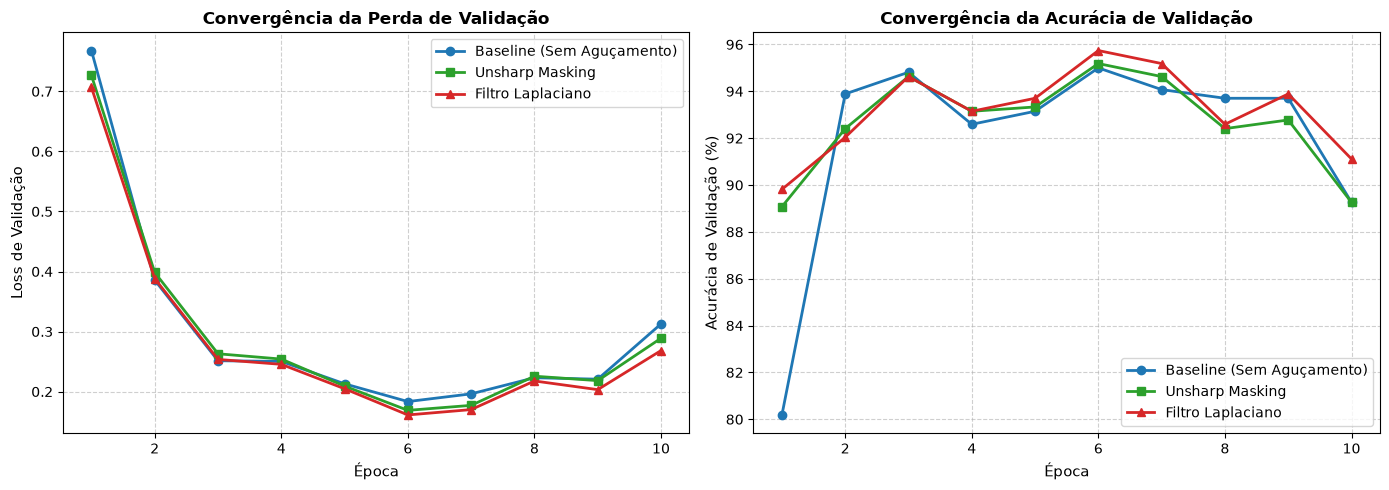

In [11]:
epochs_range = range(1, NUM_EPOCHS + 1)
plt.figure(figsize=(14, 5))

# Subplot 1: Val Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, resultado_baseline['history']['val_loss'], 'o-', label='Baseline (Sem Aguçamento)', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, resultado_unsharp['history']['val_loss'], 's-', label='Unsharp Masking', color='#2ca02c', linewidth=2)
plt.plot(epochs_range, resultado_laplacian['history']['val_loss'], '^-', label='Filtro Laplaciano', color='#d62728', linewidth=2)
plt.xlabel('Época', fontsize=11)
plt.ylabel('Loss de Validação', fontsize=11)
plt.title('Convergência da Perda de Validação', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)

# Subplot 2: Val Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, resultado_baseline['history']['val_acc'], 'o-', label='Baseline (Sem Aguçamento)', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, resultado_unsharp['history']['val_acc'], 's-', label='Unsharp Masking', color='#2ca02c', linewidth=2)
plt.plot(epochs_range, resultado_laplacian['history']['val_acc'], '^-', label='Filtro Laplaciano', color='#d62728', linewidth=2)
plt.xlabel('Época', fontsize=11)
plt.ylabel('Acurácia de Validação (%)', fontsize=11)
plt.title('Convergência da Acurácia de Validação', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)

plt.tight_layout()
out_curves_path = BASE_DIR / 'docs' / 'images' / 'agucamento_comparacao_curvas_treinamento.png'
plt.savefig(out_curves_path, dpi=300, bbox_inches='tight')
print(f'[INFO] Curvas de treino comparativas salvas em: {out_curves_path}')
plt.show()

## 7. Discussão Científica e Conclusões

Ao executar as células acima, os seguintes tópicos devem ser avaliados à luz dos resultados empíricos obtidos:
1. **Recuperação do Recall da Pista Interna:** Verificar se o Unsharp Masking ou o Laplaciano conseguiram resgatar parte das 126 amostras de `inner_race` que antes eram confundidas com `outer_race`, aumentando o *recall* e o F1-score da classe mais vulnerável da `BearingCNN`.
2. **Sensibilidade ao Ruído Sob Carga de 10 kN:** Comparar o Unsharp Masking (com *threshold* atenuador de ruído) com o filtro Laplaciano puro. Se o Laplaciano apresentar saturação ou degradação na acurácia, isso comprova matematicamente que o ruído de fundo da bancada industrial exige controle de ganho adaptativo.
3. **Detecção Binária (Normal vs. Falha):** Observar se a integridade mecânica binária permanece no patamar ótimo ($\ge 95\%$ a $100\%$), assegurando que o realce de bordas não gerou falsos alarmes na condição saudável.
